# Chapter 4 — Homogeneous Transformation Matrices

In Chapter 3 we found where the tip of a 2R arm is by drawing triangles and using
trigonometry. That works for two links in a plane, but it gets messy fast: add a third
link, or lift the arm into 3D, and you have to start the geometry over.

This chapter gives us a **systematic** tool instead. The idea:

1. Glue a **coordinate frame** to every link.
2. Describe each frame only relative to the frame **one step before it** — a small,
   local question.
3. Store each answer as one matrix, the **homogeneous transformation matrix (HTM)**, and
   chain the steps together by plain matrix multiplication.

Chapter 5 turns this into a recipe for the forward kinematics of *any* robot arm, and
Chapter 6 reuses the same frames to get velocities.

**After this chapter you should be able to:**
- write the rotation matrix $\mathbf{R}_1^0$ of a frame by looking at a drawing;
- convert the coordinates of a point from one frame to another;
- build the HTM $\mathbf{T}_1^0$ and use it to move points between frames;
- chain HTMs to get the tip of a 2R arm, and invert an HTM.

| Section | Topic |
|---------|-------|
| 4.1 | Coordinate frames — why robots need them |
| 4.2 | Posture in 2D — position, rotation matrix, 2D HTM, the 2R arm |
| 4.3 | Orientation in 3D — the 3D rotation matrix, combining rotations, other representations |
| 4.4 | The HTM in 3D — structure, composition, inverse |
| 4.5 | Chapter summary and practice problems |

### Notation (the same as in Chapters 5 and 6)

| Symbol | Meaning |
|--------|---------|
| $\{0\}, \{1\}, \{2\}, \dots$ | coordinate frames; $\{0\}$ is fixed to the ground |
| $x_1, y_1, z_1$ and $o_1$ | the axes and the origin of frame $\{1\}$ |
| $\mathbf{q}^0$ | coordinates of a point $q$ **expressed in** frame $\{0\}$ |
| $\mathbf{o}_1^0$ | the origin of frame $\{1\}$, expressed in frame $\{0\}$ (position) |
| $\mathbf{x}_1^0, \mathbf{y}_1^0, \mathbf{z}_1^0$ | unit vectors along $x_1, y_1, z_1$, expressed in frame $\{0\}$ |
| $\mathbf{R}_1^0$ | rotation matrix: **orientation** of frame $\{1\}$ relative to frame $\{0\}$ |
| $\mathbf{T}_1^0$ | HTM: **posture** (position *and* orientation) of frame $\{1\}$ relative to frame $\{0\}$ |
| $\tilde{\mathbf{q}}^0$ | $\mathbf{q}^0$ with a 1 added at the bottom ("augmented" coordinates) |

**How to read the indices:** the *subscript* names the frame being described, the
*superscript* names the frame we are looking from. So $\mathbf{T}_1^0$ is "frame 1, seen
from frame 0". In code we write `T10` for $\mathbf{T}_1^0$ and `R10` for $\mathbf{R}_1^0$ —
the same naming as Chapter 5.

Colors in every plot: $x$ axis **red**, $y$ axis **green**, $z$ axis **blue**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D          # enables 3D projection
from ipywidgets import interact, FloatSlider, ToggleButtons
from scipy.spatial.transform import Rotation, Slerp
import sympy as sp
from IPython.display import display, Math
%matplotlib inline

np.set_printoptions(precision=4, suppress=True)

AXIS_COLORS = ('red', 'green', 'blue')          # x, y, z  (same as Chapters 5 and 6)

## 4.1  Coordinate Frames — Why Robots Need Them

### Giving directions, robot-style

When you give a friend directions to a coffee shop you don't say "it is 214 m east and
118 m north of the North Pole." You say *"walk out the door, go two blocks, turn left,
it's the second building on your right."* Each instruction is relative to **where the
previous instruction left you**. A coordinate frame is exactly that: a local point of
view that nearby things are measured from.

### What is a coordinate frame?

A frame is an **origin** $o$ plus perpendicular **unit-length axes** — $x, y$ in 2D, and
$x, y, z$ in 3D. Once a frame is chosen, "where is this point?" has a precise answer:
its coordinates in that frame.

### One frame per link

A robot arm is a chain of rigid links connected by joints. We glue a frame to every
link, so the frame moves with the link (lecture notes, Lecture 5):

- Frame $\{0\}$: fixed to the base (the ground). It never moves.
- Frame $\{1\}$: attached to link 1, moves with joint 1.
- Frame $\{2\}$: attached to link 2, moves with joints 1 *and* 2.
- … and so on, up to frame $\{n\}$ at the last link.

### The big idea: describe one step at a time

Let $\mathbf{T}_i^{i-1}$ represent the **posture** (position and orientation) of frame
$\{i\}$ relative to frame $\{i-1\}$ — one step back along the chain. This is an easy,
local question: it only depends on the joint and the link *between* those two frames.
Then the posture of the last frame relative to the ground is just the product

$$\mathbf{T}_n^0 = \mathbf{T}_1^0\,\mathbf{T}_2^1\,\mathbf{T}_3^2\cdots\mathbf{T}_n^{n-1}.$$

Notice how the indices "cancel" between neighbors ($^0_1\,{}^1_2 \to {}^0_2$). This
works for 2 links or 20, in 2D or 3D. The rest of the chapter builds the matrix
$\mathbf{T}$ that makes this possible.


<p align="center"><img src="Fig4-01_frames_on_links.png" width="420"></p>

<p align="center"><i>Figure 4.1 — One frame per link. Chaining the one-step postures gives the last frame relative to the ground.</i></p>

The widget below shows frames $\{0\}$, $\{1\}$, $\{2\}$ on the 2R arm from Chapter 3,
placed as in the lecture notes: frame $\{1\}$ at the elbow with $x_1$ along link 1, and
frame $\{2\}$ at the tip with $x_2$ along link 2. Move the sliders: frame $\{1\}$ only
reacts to $\theta_1$, while frame $\{2\}$ is carried by *both* joints.

In [2]:
def rot2(theta):
    # 2x2 rotation matrix for an angle theta (radians), counter-clockwise.
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s],
                     [s,  c]])


def draw_frame_2d(ax, R, origin, name='', scale=0.25):
    # Draw a 2D frame: column 1 of R is the x axis (red), column 2 the y axis (green).
    o = np.asarray(origin, float)
    for i, (col, lbl) in enumerate(zip(AXIS_COLORS[:2], 'xy')):
        v = R[:, i] * scale
        ax.annotate('', xy=o + v, xytext=o,
                    arrowprops=dict(arrowstyle='->', color=col, lw=2))
        ax.text(*(o + v * 1.35), f'${lbl}_{{{name}}}$' if name else lbl,
                color=col, fontsize=10, fontweight='bold')
    if name:
        ax.text(o[0] - 0.16, o[1] - 0.16, '{' + name + '}', fontsize=11, fontweight='bold')


def frames_on_2R_demo(theta1_deg, theta2_deg):
    L1, L2 = 1.0, 0.8
    t1, t2 = np.radians(theta1_deg), np.radians(theta2_deg)

    # frame {1} at the elbow (x1 along link 1), frame {2} at the tip (x2 along link 2)
    R10, o10 = rot2(t1),      np.array([L1*np.cos(t1), L1*np.sin(t1)])
    R20, o20 = rot2(t1 + t2), o10 + np.array([L2*np.cos(t1+t2), L2*np.sin(t1+t2)])

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot([0, o10[0]], [0, o10[1]], color='steelblue', lw=6, solid_capstyle='round')
    ax.plot([o10[0], o20[0]], [o10[1], o20[1]], color='tomato', lw=6, solid_capstyle='round')
    draw_frame_2d(ax, np.eye(2), [0, 0], '0')
    draw_frame_2d(ax, R10, o10, '1')
    draw_frame_2d(ax, R20, o20, '2')

    r = L1 + L2 + 0.3
    ax.set_xlim(-r, r); ax.set_ylim(-r, r)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
    ax.set_title('Each link carries its own frame', fontsize=11)
    ax.set_xlabel('$x_0$'); ax.set_ylabel('$y_0$')
    plt.tight_layout(); plt.show()


interact(frames_on_2R_demo,
         theta1_deg=FloatSlider(value=45, min=-180, max=180, step=1, description='θ₁ (°)'),
         theta2_deg=FloatSlider(value=60, min=-180, max=180, step=1, description='θ₂ (°)'));

interactive(children=(FloatSlider(value=45.0, description='θ₁ (°)', max=180.0, min=-180.0, step=1.0), FloatSli…

> **Key Takeaways — Section 4.1**
> - A coordinate frame = an origin + perpendicular unit axes.
> - Attach one frame to each link; the frame moves with its link.
> - Describe each frame relative to the one before it, $\mathbf{T}_i^{i-1}$, then chain:
>   $\mathbf{T}_n^0 = \mathbf{T}_1^0\,\mathbf{T}_2^1\cdots\mathbf{T}_n^{n-1}$.

## 4.2  Posture in 2D

The **posture** of frame $\{1\}$ relative to frame $\{0\}$ has two parts:

- **position** — *where* is the origin $o_1$?
- **orientation** — *which way* do the axes $x_1, y_1$ point?


<p align="center"><img src="Fig4-02_posture_2D.png" width="380"></p>

<p align="center"><i>Figure 4.2 — Posture of frame {1} relative to frame {0}: position o<sub>1</sub><sup>0</sup> and orientation θ.</i></p>

### 4.2.1  Position

The position is the vector from $o_0$ to $o_1$, written in frame $\{0\}$:

$$\mathbf{o}_1^0 = \begin{bmatrix} 6 \\ 3 \end{bmatrix}
\quad\leftarrow\ \text{6 = $x$ coordinate in frame } \{0\},\ \ 3 = y \text{ coordinate in frame } \{0\}.$$

(Seen from frame $\{1\}$ itself, its own origin is always $\mathbf{o}_1^1 = [0,\ 0]^\top$.
The superscript matters!)

### 4.2.2  Orientation: the 2D rotation matrix

Frame $\{1\}$ is turned counter-clockwise by $\theta$ relative to frame $\{0\}$. We record
its orientation by writing **its own axes in frame $\{0\}$**, side by side:

$$\mathbf{R}_1^0 = \begin{bmatrix}\mathbf{x}_1^0 & \mathbf{y}_1^0\end{bmatrix},
\qquad
\begin{aligned}
\mathbf{x}_1^0 &= \text{unit vector along } x_1 \text{, expressed in frame } \{0\}\\
\mathbf{y}_1^0 &= \text{unit vector along } y_1 \text{, expressed in frame } \{0\}
\end{aligned}$$

From the drawing, the unit vector $x_1$ has a component $\cos\theta$ along $x_0$ and
$\sin\theta$ along $y_0$; the unit vector $y_1$ has $-\sin\theta$ along $x_0$ and
$\cos\theta$ along $y_0$. So

$$\mathbf{R}_1^0 = \begin{bmatrix}\cos\theta & -\sin\theta \\ \sin\theta & \cos\theta\end{bmatrix}.$$

**Another way to get the entries — dot products.** Recall the inner (dot) product
$\mathbf{A}\cdot\mathbf{B} = \|\mathbf{A}\|\,\|\mathbf{B}\|\cos\theta$. If $\mathbf{B}$ is a
unit vector, $\mathbf{A}\cdot\mathbf{B}$ is simply the length of the shadow of
$\mathbf{A}$ on $\mathbf{B}$, i.e. the component of $\mathbf{A}$ along $\mathbf{B}$. So
every entry of the rotation matrix is "how much of one axis lies along another":

$$\mathbf{R}_1^0 = \begin{bmatrix} x_1\cdot x_0 & y_1\cdot x_0 \\ x_1\cdot y_0 & y_1\cdot y_0 \end{bmatrix}.$$


<p align="center"><img src="Fig4-03_dot_product.png" width="380"></p>

<p align="center"><i>Figure 4.3 — The dot product with a unit vector is the length of the shadow (projection).</i></p>

Column 1 is $x_1$ seen from frame $\{0\}$, column 2 is $y_1$ seen from frame $\{0\}$.
Move the slider and watch the printed columns follow the red and green arrows.

In [3]:
def rotation_demo(theta_deg):
    theta = np.radians(theta_deg)
    R10 = rot2(theta)
    shape = np.array([[0, 0], [1, 0], [1, .2], [.2, .2], [.2, 1], [0, 1], [0, 0]]).T   # an "L" shape

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, R, title in zip(axes, [np.eye(2), R10],
                            ['Frame {0}', f'Frame {{1}}, turned by θ = {theta_deg:.0f}°']):
        pts = R @ shape
        ax.fill(pts[0], pts[1], alpha=0.3, color='steelblue')
        ax.plot(pts[0], pts[1], color='steelblue', lw=2)
        for vec, col, lbl in [(R[:, 0], 'red', 'x'), (R[:, 1], 'green', 'y')]:
            ax.annotate('', xy=0.5*vec, xytext=[0, 0],
                        arrowprops=dict(arrowstyle='->', color=col, lw=2.5))
            ax.text(*(0.6*vec), lbl, color=col, fontsize=13, fontweight='bold')
        ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
        ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
        ax.set_title(title, fontsize=12)
        ax.set_xlabel('$x_0$'); ax.set_ylabel('$y_0$')

    print(f'R_1^0 =\n{R10}')
    print(f'\ncolumn 1 = x_1 in frame 0: {R10[:, 0]}')
    print(f'column 2 = y_1 in frame 0: {R10[:, 1]}')
    plt.tight_layout(); plt.show()


interact(rotation_demo,
         theta_deg=FloatSlider(value=30, min=-180, max=180, step=5, description='θ (°)'));

interactive(children=(FloatSlider(value=30.0, description='θ (°)', max=180.0, min=-180.0, step=5.0), Output())…

### 4.2.3  A rotation matrix converts coordinates between frames

Here is the main job of a rotation matrix (Lecture 6). Frames $\{0\}$ and $\{1\}$ share
an origin; $x_1$ points along $y_0$ and $y_1$ points along $-x_0$ (frame $\{1\}$ is
turned by $90^\circ$). 
<p align="center"><img src="Fig4-04_rotation_converts_coordinates.png" width="400"></p>

<p align="center"><i>Figure 4.4 — Lecture 6 example: the same point p described in frame {0} and in frame {1}.</i></p>

Read the columns off the drawing:

$$\mathbf{R}_1^0 = \begin{bmatrix}\mathbf{x}_1^0 & \mathbf{y}_1^0\end{bmatrix}
= \begin{bmatrix}0 & -1\\ 1 & 0\end{bmatrix}.$$

A point $p$ sits at 1 along $x_0$ and 1 along $y_0$, so $\mathbf{p}^0 = [1,\ 1]^\top$.
Measured along frame $\{1\}$'s axes it is 1 along $x_1$ and $-1$ along $y_1$, so
$\mathbf{p}^1 = [1,\ -1]^\top$. The rotation matrix connects the two:

$$\mathbf{p}^0 = \mathbf{R}_1^0\,\mathbf{p}^1 =
\begin{bmatrix}0 & -1\\ 1 & 0\end{bmatrix}\begin{bmatrix}1\\-1\end{bmatrix}
= \begin{bmatrix}0\cdot1 + (-1)(-1)\\ 1\cdot1 + 0\cdot(-1)\end{bmatrix}
= \begin{bmatrix}1\\1\end{bmatrix}. \checkmark$$

**Going the other way.** Swap the roles of the frames: $\mathbf{R}_0^1 =
[\mathbf{x}_0^1\ \ \mathbf{y}_0^1]$ holds frame $\{0\}$'s axes seen from frame $\{1\}$.
From the drawing, $x_0$ points along $-y_1$ and $y_0$ along $x_1$:

$$\mathbf{R}_0^1 = \begin{bmatrix}0 & 1\\ -1 & 0\end{bmatrix} = \left(\mathbf{R}_1^0\right)^\top,
\qquad \mathbf{p}^1 = \mathbf{R}_0^1\,\mathbf{p}^0 = \begin{bmatrix}1\\-1\end{bmatrix}. \checkmark$$

So **to go back, just transpose** — no matrix inversion needed.

<details>
<summary><b>Why is the inverse just the transpose?</b> (click to expand)</summary>

The entries of $\mathbf{R}_1^0$ are dot products: row $i$, column $j$ is
(axis $j$ of frame 1)$\cdot$(axis $i$ of frame 0). For $\mathbf{R}_0^1$ the roles swap,
which swaps rows and columns — a transpose. Since going $0\to1\to0$ must change nothing,
$\mathbf{R}_0^1\mathbf{R}_1^0 = \mathbf{I}$, i.e. $(\mathbf{R}_1^0)^{-1} = (\mathbf{R}_1^0)^\top$.
</details>

**Three properties every rotation matrix has:**

| Property | In plain words |
|----------|----------------|
| $(\mathbf{R}_1^0)^\top\mathbf{R}_1^0 = \mathbf{I}$ | the columns are unit vectors at right angles to each other |
| $(\mathbf{R}_1^0)^{-1} = (\mathbf{R}_1^0)^\top = \mathbf{R}_0^1$ | going back is a transpose |
| $\det(\mathbf{R}_1^0) = +1$ | it only turns things — no stretching and no mirror image |

In [4]:
# Lecture 6 example: x1 along y0, y1 along -x0
R10 = np.array([[0, -1],
                [1,  0]])          # columns: x_1^0, y_1^0
p1  = np.array([1, -1])            # p in frame {1}

p0 = R10 @ p1
print('p^0 = R_1^0 p^1      =', p0)

R01 = R10.T                        # R_0^1 = (R_1^0)^T
print('R_0^1 =\n', R01)
print('p^1 = R_0^1 p^0      =', R01 @ p0)

print('\nR^T R = I ?', np.allclose(R10.T @ R10, np.eye(2)),
      '    det(R) =', round(np.linalg.det(R10), 6))
print('R_1^0 equals rot2(90°)?', np.allclose(R10, rot2(np.radians(90))))

p^0 = R_1^0 p^1      = [1 1]
R_0^1 =
 [[ 0  1]
 [-1  0]]
p^1 = R_0^1 p^0      = [ 1 -1]

R^T R = I ? True     det(R) = 1.0
R_1^0 equals rot2(90°)? True


### 4.2.4  Combining two rotations in 2D

If frame $\{2\}$ is turned by $\beta$ relative to frame $\{1\}$, and frame $\{1\}$ is
turned by $\alpha$ relative to frame $\{0\}$, the indices chain just like in Section 4.1:

$$\mathbf{R}_2^0 = \mathbf{R}_1^0\,\mathbf{R}_2^1 = \mathbf{R}(\alpha)\,\mathbf{R}(\beta) = \mathbf{R}(\alpha+\beta).$$

In 2D the angles simply add, so the order does not matter:
$\mathbf{R}(\alpha)\mathbf{R}(\beta) = \mathbf{R}(\beta)\mathbf{R}(\alpha)$. For the 2R arm
this is the familiar fact that link 2 points at the angle $\theta_1+\theta_2$.

> **Careful:** this "order does not matter" is special to 2D. In 3D the order of
> rotations **does** matter (Section 4.3.2).

In [5]:
def composition_2d_demo(alpha_deg, beta_deg):
    Ra, Rb = rot2(np.radians(alpha_deg)), rot2(np.radians(beta_deg))
    shape = np.array([[0, 0], [1, 0], [1, .2], [.2, .2], [.2, 1], [0, 1], [0, 0]]).T

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (R, ttl) in zip(axes, [(np.eye(2), 'Frame {0}'),
                                   (Ra @ Rb, f'R({alpha_deg:.0f}°) R({beta_deg:.0f}°)'),
                                   (Rb @ Ra, f'R({beta_deg:.0f}°) R({alpha_deg:.0f}°)')]):
        pts = R @ shape
        ax.fill(pts[0], pts[1], alpha=0.3, color='steelblue')
        ax.plot(pts[0], pts[1], 'steelblue', lw=2)
        for vec, col in [(R[:, 0], 'red'), (R[:, 1], 'green')]:
            ax.annotate('', xy=0.45*vec, xytext=[0, 0],
                        arrowprops=dict(arrowstyle='->', color=col, lw=2.5))
        ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
        ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
        ax.set_title(ttl, fontsize=11)

    print('R(α)R(β) = R(α+β)?            ', np.allclose(Ra @ Rb, rot2(np.radians(alpha_deg + beta_deg))))
    print('R(α)R(β) = R(β)R(α)?  (2D only)', np.allclose(Ra @ Rb, Rb @ Ra))
    plt.tight_layout(); plt.show()


interact(composition_2d_demo,
         alpha_deg=FloatSlider(value=45, min=-180, max=180, step=5, description='α (°)'),
         beta_deg =FloatSlider(value=30, min=-180, max=180, step=5, description='β (°)'));

interactive(children=(FloatSlider(value=45.0, description='α (°)', max=180.0, min=-180.0, step=5.0), FloatSlid…

### 4.2.5  Position + orientation together: the 2D HTM

Now frame $\{1\}$ is both **moved** (origin at $\mathbf{o}_1^0$) and **turned**
($\mathbf{R}_1^0$). A point $q$ has coordinates $\mathbf{q}^1$ in frame $\{1\}$. Where is it
in frame $\{0\}$? Think of it as two moves (Lecture 6):

1. **Turn** the arrow from $o_1$ to $q$ into frame-$\{0\}$ directions: $\mathbf{R}_1^0\,\mathbf{q}^1$.
2. **Add** where that arrow starts, $o_1$: $+\ \mathbf{o}_1^0$.

$$\boxed{\mathbf{q}^0 = \mathbf{R}_1^0\,\mathbf{q}^1 + \mathbf{o}_1^0}$$


<p align="center"><img src="Fig4-05_HTM_2D.png" width="420"></p>

<p align="center"><i>Figure 4.5 — A point q seen from a moved and turned frame: q<sup>0</sup> = R<sub>1</sub><sup>0</sup> q<sup>1</sup> + o<sub>1</sub><sup>0</sup>.</i></p>

That's correct, but it is a multiply *and* an add. With many frames in a chain we'd
alternate multiply, add, multiply, add… There's a neat trick to fold both into **one
multiplication**: put a 1 under each point and pack $\mathbf{R}_1^0$ and $\mathbf{o}_1^0$
into one bigger matrix:

$$\underbrace{\begin{bmatrix}\mathbf{q}^0\\1\end{bmatrix}}_{\tilde{\mathbf{q}}^0}
=
\underbrace{\begin{bmatrix}\mathbf{R}_1^0 & \mathbf{o}_1^0\\ 0\ \ 0 & 1\end{bmatrix}}_{\mathbf{T}_1^0\ (3\times3)}
\underbrace{\begin{bmatrix}\mathbf{q}^1\\1\end{bmatrix}}_{\tilde{\mathbf{q}}^1},
\qquad\text{written out:}\qquad
\begin{bmatrix}q_x^0\\ q_y^0\\ 1\end{bmatrix} =
\begin{bmatrix} r_{11} & r_{12} & o_x \\ r_{21} & r_{22} & o_y \\ 0 & 0 & 1\end{bmatrix}
\begin{bmatrix}q_x^1\\ q_y^1\\ 1\end{bmatrix}.$$

Multiply the first two rows out and you get exactly $\mathbf{q}^0 = \mathbf{R}_1^0\mathbf{q}^1 + \mathbf{o}_1^0$;
the third row just says $1 = 1$. The extra row and column are bookkeeping, not new physics.
$\mathbf{T}_1^0$ is the **homogeneous transformation matrix**: the posture (position and
orientation) of frame $\{1\}$ relative to frame $\{0\}$.

$$\tilde{\mathbf{q}}^0 = \mathbf{T}_1^0\,\tilde{\mathbf{q}}^1 \qquad\text{and, going back,}\qquad
\tilde{\mathbf{q}}^1 = \mathbf{T}_0^1\,\tilde{\mathbf{q}}^0,\quad \mathbf{T}_0^1 = \left(\mathbf{T}_1^0\right)^{-1}.$$

**Worked example.** Frame $\{1\}$ has its origin at $\mathbf{o}_1^0 = [1,\ 1]^\top$ and is
turned by $90^\circ$ ($x_1$ along $y_0$, $y_1$ along $-x_0$). A point is 1 unit along
$x_1$: $\mathbf{q}^1 = [1,\ 0]^\top$. Then

$$\tilde{\mathbf{q}}^0 = \mathbf{T}_1^0\,\tilde{\mathbf{q}}^1 =
\begin{bmatrix}0 & -1 & 1\\ 1 & 0 & 1\\ 0 & 0 & 1\end{bmatrix}
\begin{bmatrix}1\\0\\1\end{bmatrix} =
\begin{bmatrix}0\cdot1 + (-1)\cdot0 + 1\cdot1\\ 1\cdot1 + 0\cdot0 + 1\cdot1\\ 0+0+1\end{bmatrix} =
\begin{bmatrix}1\\2\\1\end{bmatrix}
\ \Rightarrow\ \mathbf{q}^0 = \begin{bmatrix}1\\2\end{bmatrix}.$$

Sanity check with a sketch: start at $o_1 = (1,1)$ and walk 1 unit along $x_1$, which
points "up" ($+y_0$). You land at $(1, 2)$. ✓

In [6]:
def htm_2d(theta, o):
    # 3x3 HTM T_1^0 from the angle theta of frame {1} and its origin o = o_1^0.
    T = np.eye(3)
    T[:2, :2] = rot2(theta)
    T[:2,  2] = o
    return T


# Worked example: o_1^0 = (1, 1), frame {1} turned by 90°, q^1 = (1, 0)
T10 = htm_2d(np.radians(90), [1, 1])
q1  = np.array([1, 0])

q0_two_steps = T10[:2, :2] @ q1 + T10[:2, 2]     # R_1^0 q^1 + o_1^0
q0_tilde     = T10 @ np.append(q1, 1)            # T_1^0 [q^1; 1]

print('T_1^0 =\n', T10)
print('\nR q1 + o          :', q0_two_steps)
print('T_1^0 [q1; 1]     :', q0_tilde, ' -> q^0 =', q0_tilde[:2])

T01 = np.linalg.inv(T10)                         # T_0^1 = (T_1^0)^-1  (Section 4.4.3 shows a shortcut)
print('\nBack again, T_0^1 [q0; 1] :', T01 @ q0_tilde, ' -> q^1 =', (T01 @ q0_tilde)[:2])

T_1^0 =
 [[ 0. -1.  1.]
 [ 1.  0.  1.]
 [ 0.  0.  1.]]

R q1 + o          : [1. 2.]
T_1^0 [q1; 1]     : [1. 2. 1.]  -> q^0 = [1. 2.]

Back again, T_0^1 [q0; 1] : [1. 0. 1.]  -> q^1 = [1. 0.]


### 4.2.6  Example: forward kinematics of the 2R arm with HTMs

Let's redo the Chapter 3 problem with HTMs (Lecture 6). Frames as in the widget of
Section 4.1: frame $\{1\}$ at the elbow with $x_1$ along link 1, frame $\{2\}$ at the tip
with $x_2$ along link 2. Shorthand: $c_1 = \cos\theta_1$, $s_1 = \sin\theta_1$, and so on.


<p align="center"><img src="Fig4-06_2R_frames.png" width="360"></p>

<p align="center"><i>Figure 4.6 — The 2R arm with frame {1} at the elbow and frame {2} at the tip (as in the lecture notes).</i></p>

**Step 1 — frame $\{1\}$ relative to frame $\{0\}$.** $x_1$ is turned by $\theta_1$, and
$o_1$ is at the end of link 1:

$$\mathbf{T}_1^0 = \begin{bmatrix}\mathbf{R}_1^0 & \mathbf{o}_1^0\\ 0\ \ 0 & 1\end{bmatrix}
= \begin{bmatrix} c_1 & -s_1 & L_1c_1\\ s_1 & c_1 & L_1s_1\\ 0 & 0 & 1\end{bmatrix}.$$

**Step 2 — frame $\{2\}$ relative to frame $\{1\}$.** Seen from frame $\{1\}$, link 2 is
turned by $\theta_2$ and has length $L_2$ — *exactly the same form*:

$$\mathbf{T}_2^1 = \begin{bmatrix}\mathbf{R}_2^1 & \mathbf{o}_2^1\\ 0\ \ 0 & 1\end{bmatrix}
= \begin{bmatrix} c_2 & -s_2 & L_2c_2\\ s_2 & c_2 & L_2s_2\\ 0 & 0 & 1\end{bmatrix}.$$

**Step 3 — chain them.** The tip is the origin $o_2$. In its own frame it is
$\mathbf{o}_2^2 = [0,\ 0]^\top$, so

$$\tilde{\mathbf{o}}_2^0 = \mathbf{T}_1^0\,\mathbf{T}_2^1\,\tilde{\mathbf{o}}_2^2
= \mathbf{T}_1^0\,\mathbf{T}_2^1\begin{bmatrix}0\\0\\1\end{bmatrix}
= \mathbf{T}_1^0\begin{bmatrix}L_2c_2\\ L_2s_2\\ 1\end{bmatrix}
= \begin{bmatrix}L_2c_1c_2 - L_2s_1s_2 + L_1c_1\\ L_2s_1c_2 + L_2c_1s_2 + L_1s_1\\ 1\end{bmatrix}.$$

Using $\cos(\theta_1+\theta_2) = c_1c_2 - s_1s_2$ and $\sin(\theta_1+\theta_2) = s_1c_2 + c_1s_2$:

$$\mathbf{o}_2^0 = \begin{bmatrix}L_1\cos\theta_1 + L_2\cos(\theta_1+\theta_2)\\ L_1\sin\theta_1 + L_2\sin(\theta_1+\theta_2)\end{bmatrix}$$

— exactly the Chapter 3 answer, but now produced by a **recipe** (write one HTM per link,
multiply) instead of by staring at triangles. The product $\mathbf{T}_2^0 = \mathbf{T}_1^0\mathbf{T}_2^1$
also gives the tip's orientation for free: its rotation block is $\mathbf{R}(\theta_1+\theta_2)$.

> Chapter 5 places the frames slightly differently (frame $\{i\}$ sits *on* joint $i$, with
> $z_i$ along the joint axis, and an extra frame $\{e\}$ at the gripper). That choice makes
> the recipe work for any 3D robot. The tip position comes out the same.

The cell below lets SymPy do the algebra of Step 3 for us.

In [7]:
t1, t2, L1s, L2s = sp.symbols('theta_1 theta_2 L_1 L_2', real=True)

def sym_htm_2d(theta, L):
    # Symbolic T_i^{i-1} for a planar link: turned by theta, origin at the end of a link of length L.
    c, s = sp.cos(theta), sp.sin(theta)
    return sp.Matrix([[c, -s, L*c],
                      [s,  c, L*s],
                      [0,  0, 1]])

T10_s = sym_htm_2d(t1, L1s)
T21_s = sym_htm_2d(t2, L2s)
T20_s = sp.simplify(T10_s * T21_s)            # T_2^0 = T_1^0 T_2^1

display(Math(r'\mathbf{T}_2^0 = \mathbf{T}_1^0\,\mathbf{T}_2^1 = ' + sp.latex(T20_s)))
display(Math(r'\tilde{\mathbf{o}}_2^0 = \mathbf{T}_2^0\,[0,\ 0,\ 1]^\top = '
             + sp.latex(sp.simplify(T20_s * sp.Matrix([0, 0, 1])))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [8]:
def fk_ch3(theta1, theta2, L1=1.0, L2=0.8):
    # The Chapter 3 trig formula, used as the answer to check against.
    return np.array([L1*np.cos(theta1) + L2*np.cos(theta1 + theta2),
                     L1*np.sin(theta1) + L2*np.sin(theta1 + theta2)])


def htm_chain_demo(theta1_deg, theta2_deg):
    L1, L2 = 1.0, 0.8
    t1, t2 = np.radians(theta1_deg), np.radians(theta2_deg)

    T10 = htm_2d(t1, [L1*np.cos(t1), L1*np.sin(t1)])    # frame {1} relative to frame {0}
    T21 = htm_2d(t2, [L2*np.cos(t2), L2*np.sin(t2)])    # frame {2} relative to frame {1}
    T20 = T10 @ T21                                     # chain: frame {2} relative to frame {0}

    o10, o20 = T10[:2, 2], T20[:2, 2]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot([0, o10[0]], [0, o10[1]], color='steelblue', lw=6, solid_capstyle='round')
    ax.plot([o10[0], o20[0]], [o10[1], o20[1]], color='tomato', lw=6, solid_capstyle='round')
    draw_frame_2d(ax, np.eye(2), [0, 0], '0')
    draw_frame_2d(ax, T10[:2, :2], o10, '1')
    draw_frame_2d(ax, T20[:2, :2], o20, '2')
    ax.plot(*o20, 'g*', markersize=15, zorder=5)
    r = L1 + L2 + 0.3
    ax.set_xlim(-r, r); ax.set_ylim(-r, r)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
    ax.set_title(f'Tip from the HTM chain: ({o20[0]:.3f}, {o20[1]:.3f})', fontsize=11)
    ax.set_xlabel('$x_0$'); ax.set_ylabel('$y_0$')
    plt.tight_layout(); plt.show()

    print('Tip from T_1^0 T_2^1       :', o20)
    print('Tip from the Chapter 3 formula:', fk_ch3(t1, t2, L1, L2))
    print('Match?', np.allclose(o20, fk_ch3(t1, t2, L1, L2)))


interact(htm_chain_demo,
         theta1_deg=FloatSlider(value=45, min=-180, max=180, step=1, description='θ₁ (°)'),
         theta2_deg=FloatSlider(value=60, min=-180, max=180, step=1, description='θ₂ (°)'));

interactive(children=(FloatSlider(value=45.0, description='θ₁ (°)', max=180.0, min=-180.0, step=1.0), FloatSli…

> **Key Takeaways — Section 4.2**
> - Posture = position $\mathbf{o}_1^0$ + orientation $\mathbf{R}_1^0$.
> - $\mathbf{R}_1^0 = [\mathbf{x}_1^0\ \ \mathbf{y}_1^0]$: the columns are frame $\{1\}$'s axes written in frame $\{0\}$. Each entry is a dot product of two axes.
> - A rotation matrix converts coordinates: $\mathbf{p}^0 = \mathbf{R}_1^0\mathbf{p}^1$; to go back, transpose: $\mathbf{R}_0^1 = (\mathbf{R}_1^0)^\top$.
> - Moved *and* turned frame: $\mathbf{q}^0 = \mathbf{R}_1^0\mathbf{q}^1 + \mathbf{o}_1^0$, or in one step $\tilde{\mathbf{q}}^0 = \mathbf{T}_1^0\tilde{\mathbf{q}}^1$ with $\mathbf{T}_1^0 = \begin{bmatrix}\mathbf{R}_1^0 & \mathbf{o}_1^0\\ \mathbf{0}^\top & 1\end{bmatrix}$.
> - Chaining frames is matrix multiplication: $\mathbf{T}_2^0 = \mathbf{T}_1^0\mathbf{T}_2^1$. For the 2R arm this reproduces Chapter 3's formula.

## 4.3  Orientation in 3D

### 4.3.1  The 3D rotation matrix

Everything from 2D carries over — we just add the $z$ axis (Lecture 7). The orientation
of frame $\{1\}$ relative to frame $\{0\}$ is again "frame 1's axes, written in frame 0":

$$\mathbf{R}_1^0 = \begin{bmatrix}\mathbf{x}_1^0 & \mathbf{y}_1^0 & \mathbf{z}_1^0\end{bmatrix}
= \begin{bmatrix}
x_1\cdot x_0 & y_1\cdot x_0 & z_1\cdot x_0\\
x_1\cdot y_0 & y_1\cdot y_0 & z_1\cdot y_0\\
x_1\cdot z_0 & y_1\cdot z_0 & z_1\cdot z_0
\end{bmatrix}_{3\times3}$$

For simple drawings where every axis of frame $\{1\}$ lines up with some axis of frame
$\{0\}$, each column is just one $\pm1$ and two zeros: ask *"which way does $x_1$
point, in frame-0 terms?"*

**Example 1.** $x_1$ points along $z_0$, $y_1$ points along $x_0$, $z_1$ points along $y_0$:

$$\mathbf{R}_1^0 = \begin{bmatrix}\mathbf{x}_1^0 & \mathbf{y}_1^0 & \mathbf{z}_1^0\end{bmatrix}
= \begin{bmatrix}0 & 1 & 0\\ 0 & 0 & 1\\ 1 & 0 & 0\end{bmatrix},
\qquad
\mathbf{R}_0^1 = \left(\mathbf{R}_1^0\right)^\top = \begin{bmatrix}0 & 0 & 1\\ 1 & 0 & 0\\ 0 & 1 & 0\end{bmatrix}.$$


<p align="center"><img src="Fig4-07_3D_example1.png" width="320"></p>

<p align="center"><i>Figure 4.7 — Example 1: every axis of frame {1} lines up with an axis of frame {0}.</i></p>

**Example 2 (tilted axes).** $z_0$, $x_0$, $x_1$ and $y_1$ all lie in one plane;
$x_1$ is $30^\circ$ from $z_0$, and $z_1$ points along $y_0$. Use the dot products —
for unit vectors $a\cdot b = \cos(\text{angle between them})$:

$$\mathbf{R}_1^0 = \begin{bmatrix}
\sin30^\circ & \cos30^\circ & 0\\
0 & 0 & 1\\
\cos30^\circ & -\sin30^\circ & 0
\end{bmatrix}.$$


<p align="center"><img src="Fig4-08_3D_example2.png" width="340"></p>

<p align="center"><i>Figure 4.8 — Example 2: x<sub>1</sub> is tilted 30° from z<sub>0</sub>; z<sub>1</sub> points along y<sub>0</sub>.</i></p>

**Right-hand rule check.** In a right-handed frame $z = x\times y$. You can use this to
fill in a column you can't see in the drawing, or to catch a mistake: if
$\mathbf{x}_1^0\times\mathbf{y}_1^0 \neq \mathbf{z}_1^0$ (equivalently $\det\mathbf{R}\neq+1$),
something is wrong.

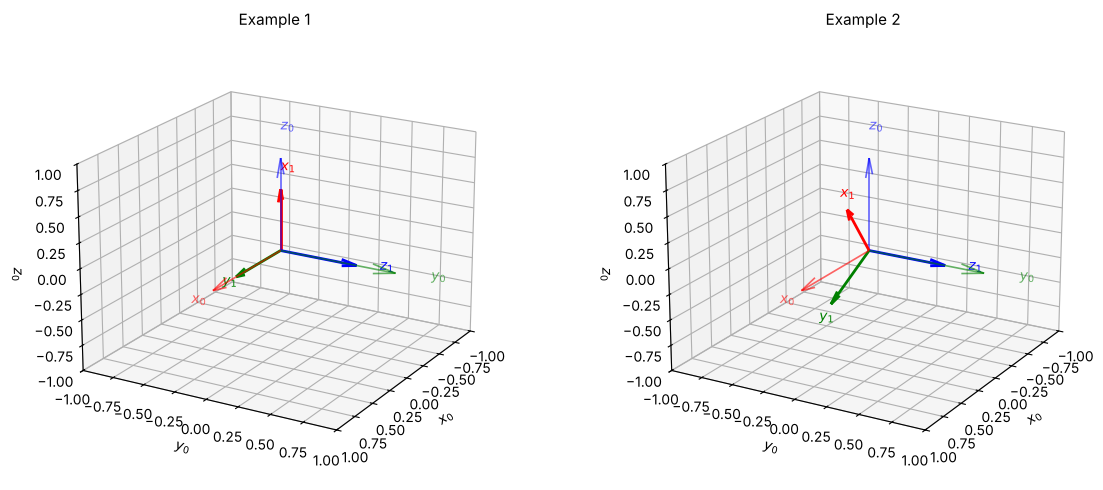

Example 1:  x1 × y1 = z1 ? True   det = 1.000   R^T R = I ? True
Example 2:  x1 × y1 = z1 ? True   det = 1.000   R^T R = I ? True

Example 1:  R_0^1 = (R_1^0)^T =
 [[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]


In [9]:
def draw_frame_3d(ax, R=None, origin=None, name='', scale=0.4, alpha=1.0):
    # Draw a 3D frame: columns of R are the x (red), y (green), z (blue) axes.
    R = np.eye(3) if R is None else R
    o = np.zeros(3) if origin is None else np.asarray(origin, float)
    for i, (col, lbl) in enumerate(zip(AXIS_COLORS, 'xyz')):
        v = R[:, i] * scale
        ax.quiver(*o, *v, color=col, alpha=alpha, arrow_length_ratio=0.2,
                  linewidth=max(0.5, 2*alpha))
        if alpha >= 0.5:
            ax.text(*(o + v*1.3), f'${lbl}_{{{name}}}$' if name else lbl,
                    color=col, fontsize=10, fontweight='bold', alpha=alpha)


def setup_3d(ax, lim=1.2, title=''):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_xlabel('$x_0$'); ax.set_ylabel('$y_0$'); ax.set_zlabel('$z_0$')
    ax.set_title(title, fontsize=11)


c30, s30 = np.cos(np.radians(30)), np.sin(np.radians(30))
R10_ex1 = np.array([[0, 1, 0],
                    [0, 0, 1],
                    [1, 0, 0]], float)
R10_ex2 = np.array([[s30,  c30, 0],
                    [0,    0,   1],
                    [c30, -s30, 0]])

fig = plt.figure(figsize=(12, 5))
for k, (R, ttl) in enumerate([(R10_ex1, 'Example 1'), (R10_ex2, 'Example 2')]):
    ax = fig.add_subplot(1, 2, k + 1, projection='3d')
    draw_frame_3d(ax, np.eye(3), name='0', scale=0.9, alpha=0.6)
    draw_frame_3d(ax, R, name='1', scale=0.6)
    setup_3d(ax, 1.0, ttl)
    ax.view_init(20, 30)
plt.tight_layout(); plt.show()

for name, R in [('Example 1', R10_ex1), ('Example 2', R10_ex2)]:
    print(f'{name}:  x1 × y1 = z1 ? {np.allclose(np.cross(R[:, 0], R[:, 1]), R[:, 2])}'
          f'   det = {np.linalg.det(R):.3f}   R^T R = I ? {np.allclose(R.T @ R, np.eye(3))}')
print('\nExample 1:  R_0^1 = (R_1^0)^T =\n', R10_ex1.T)

#### Converting coordinates in 3D

Exactly as in 2D:

$$\mathbf{q}^0 = \mathbf{R}_1^0\,\mathbf{q}^1, \qquad \mathbf{q}^1 = \mathbf{R}_0^1\,\mathbf{q}^0 = \left(\mathbf{R}_1^0\right)^\top\mathbf{q}^0.$$

**Example (Lecture 7).** Use the frames of Example 1. A point $q$ lies in the
$y_0z_0$ plane, 1 unit along $y_0$ and 1 unit along $z_0$, so $\mathbf{q}^0 = [0,\ 1,\ 1]^\top$.
Measured along frame $\{1\}$'s axes it is 1 along $x_1$ (which points along $z_0$) and 1
along $z_1$ (which points along $y_0$), so $\mathbf{q}^1 = [1,\ 0,\ 1]^\top$. Check:

$$\mathbf{R}_1^0\,\mathbf{q}^1 =
\begin{bmatrix}0 & 1 & 0\\ 0 & 0 & 1\\ 1 & 0 & 0\end{bmatrix}
\begin{bmatrix}1\\0\\1\end{bmatrix} =
\begin{bmatrix}0\cdot1 + 1\cdot0 + 0\cdot1\\ 0\cdot1 + 0\cdot0 + 1\cdot1\\ 1\cdot1 + 0\cdot0 + 0\cdot1\end{bmatrix} =
\begin{bmatrix}0\\1\\1\end{bmatrix} = \mathbf{q}^0. \checkmark$$

<p align="center"><img src="Fig4-09_3D_point_conversion.png" width="360"></p>

<p align="center"><i>Figure 4.9 — Lecture 7 example: point q in the y<sub>0</sub>z<sub>0</sub> plane, using the frames of Example 1.</i></p>

In [10]:
q1 = np.array([1, 0, 1])
q0 = R10_ex1 @ q1
print('q^0 = R_1^0 q^1 =', q0)
print('q^1 = R_0^1 q^0 =', R10_ex1.T @ q0, '  (back where we started)')

q^0 = R_1^0 q^1 = [0. 1. 1.]
q^1 = R_0^1 q^0 = [1. 0. 1.]   (back where we started)


#### The three basic rotation matrices

A rotation matrix can also describe a **motion**: start with frame $\{1\}$ on top of
frame $\{0\}$, then turn it by $\theta$ about one of frame $\{0\}$'s axes. Reading the new
axes column by column gives three special cases (Lecture 7):

$$\mathbf{R}_z(\theta) = \begin{bmatrix}\cos\theta&-\sin\theta&0\\\sin\theta&\cos\theta&0\\0&0&1\end{bmatrix},\quad
\mathbf{R}_x(\theta) = \begin{bmatrix}1&0&0\\0&\cos\theta&-\sin\theta\\0&\sin\theta&\cos\theta\end{bmatrix},\quad
\mathbf{R}_y(\theta) = \begin{bmatrix}\cos\theta&0&\sin\theta\\0&1&0\\-\sin\theta&0&\cos\theta\end{bmatrix}$$


<p align="center"><img src="Fig4-10_basic_rotations.png" width="900"></p>

<p align="center"><i>Figure 4.10 — The three basic rotations: frame {1} turned by θ about z<sub>0</sub>, x<sub>0</sub>, or y<sub>0</sub>.</i></p>

Ways to remember them:

- The axis you rotate **about** doesn't move, so its row and column are a 1 and zeros.
- The other $2\times2$ block is the 2D rotation matrix.
- $\mathbf{R}_y$ looks "flipped" (the minus sign is at the bottom left). That is not a
  typo: about $y$, the right-hand rule turns $z$ toward $x$ (the order is $z \to x$,
  not $x \to z$), so a positive $\theta$ tips $z_1$ toward $+x_0$.

In Chapter 5 these become the rotation blocks of the basic HTMs
$\mathrm{Rot}_{x,\alpha}$, $\mathrm{Rot}_{y,\beta}$, $\mathrm{Rot}_{z,\gamma}$.

In [11]:
def Rx(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[1, 0,  0],
                     [0, c, -s],
                     [0, s,  c]])

def Ry(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[ c, 0, s],
                     [ 0, 1, 0],
                     [-s, 0, c]])

def Rz(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s, 0],
                     [s,  c, 0],
                     [0,  0, 1]])


def basic_rotation_demo(axis, angle_deg):
    theta = np.radians(angle_deg)
    R10 = {'about x₀': Rx, 'about y₀': Ry, 'about z₀': Rz}[axis](theta)

    fig = plt.figure(figsize=(11, 5))
    ax = fig.add_subplot(1, 2, 1, projection='3d')
    draw_frame_3d(ax, np.eye(3), scale=0.9, alpha=0.2)
    draw_frame_3d(ax, R10, name='1', scale=0.7)
    t, r = np.linspace(0, theta, 60), 0.55          # dashed arc showing the turn
    arc = {'about x₀': [0*t, r*np.cos(t), r*np.sin(t)],
           'about y₀': [r*np.sin(t), 0*t, r*np.cos(t)],
           'about z₀': [r*np.cos(t), r*np.sin(t), 0*t]}[axis]
    ax.plot(*arc, 'k--', lw=1.5, alpha=0.6)
    setup_3d(ax, 1.0, f'Rotate {axis} by θ = {angle_deg}°')

    ax2 = fig.add_subplot(1, 2, 2); ax2.axis('off')
    rows = '\n'.join('  '.join(f'{v:7.3f}' for v in row) for row in R10)
    ax2.text(0.05, 0.6, f'R_1^0 =\n\n{rows}\n\n   x_1^0    y_1^0    z_1^0', fontsize=13,
             fontfamily='monospace', va='center', transform=ax2.transAxes,
             bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.6))
    ax2.text(0.05, 0.12, f'det = {np.linalg.det(R10):.4f}    R^T R = I ? {np.allclose(R10.T @ R10, np.eye(3))}',
             fontsize=11, fontfamily='monospace', transform=ax2.transAxes)
    plt.tight_layout(); plt.show()


interact(basic_rotation_demo,
         axis=ToggleButtons(options=['about z₀', 'about x₀', 'about y₀'], description='Axis'),
         angle_deg=FloatSlider(value=45, min=-180, max=180, step=5, description='θ (°)'));

interactive(children=(ToggleButtons(description='Axis', options=('about z₀', 'about x₀', 'about y₀'), value='a…

### 4.3.2  Combining Rotations: Order Matters, and Fixed vs. Current Axes

**In 3D, order matters.** Take a book. Turn it $90^\circ$ about $x$, then $90^\circ$ about
$y$. Now start again and do $y$ first, then $x$. The book ends up in two different
poses. So unlike 2D, we can't just add up angles; we have to multiply matrices **in the
right order**.

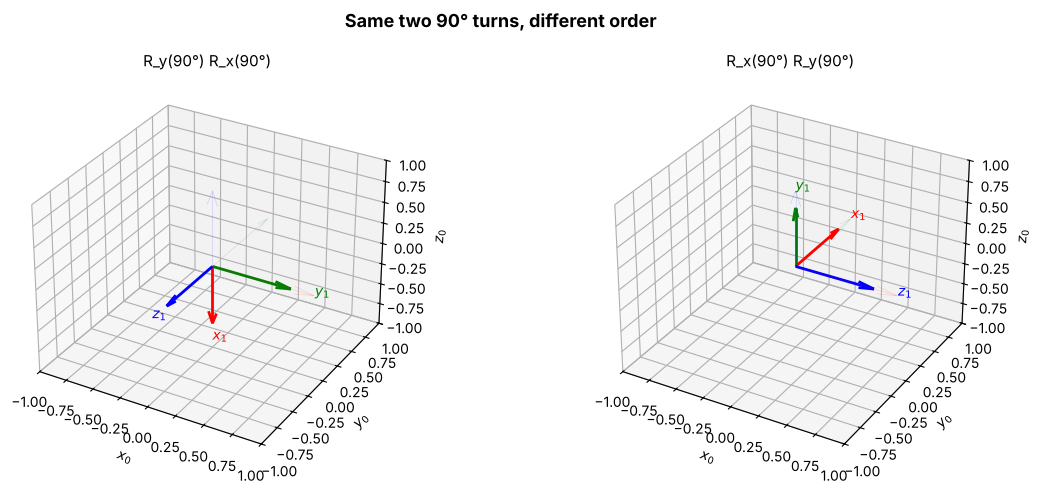

R_y(90°) R_x(90°) =
 [[ 0.  1.  0.]
 [ 0.  0. -1.]
 [-1.  0.  0.]]

R_x(90°) R_y(90°) =
 [[ 0.  0.  1.]
 [ 1.  0. -0.]
 [-0.  1.  0.]]

Equal? False  <- in 3D, order matters!


In [12]:
R_A = Ry(np.pi/2) @ Rx(np.pi/2)
R_B = Rx(np.pi/2) @ Ry(np.pi/2)

fig = plt.figure(figsize=(12, 5))
fig.suptitle('Same two 90° turns, different order', fontsize=13, fontweight='bold')
for i, (R, ttl) in enumerate([(R_A, 'R_y(90°) R_x(90°)'), (R_B, 'R_x(90°) R_y(90°)')]):
    ax = fig.add_subplot(1, 2, i + 1, projection='3d')
    draw_frame_3d(ax, np.eye(3), alpha=0.15, scale=0.9)
    draw_frame_3d(ax, R, name='1', scale=0.7)
    setup_3d(ax, 1.0, ttl)
plt.tight_layout(); plt.show()

print('R_y(90°) R_x(90°) =\n', R_A)
print('\nR_x(90°) R_y(90°) =\n', R_B)
print('\nEqual?', np.allclose(R_A, R_B), ' <- in 3D, order matters!')

**Which axis does a new rotation act about?** It depends on which side you multiply on.

| You write | The new rotation $\mathbf{R}_\text{add}$ turns the frame about … | Name |
|---|---|---|
| $\mathbf{R}_\text{current}\,\mathbf{R}_\text{add}$ | the frame's **current** (own, "body") axes | post-multiply (on the right) |
| $\mathbf{R}_\text{add}\,\mathbf{R}_\text{current}$ | the **fixed** axes of frame $\{0\}$ | pre-multiply (on the left) |

**Why the right side means "current axes".** Write it with frames:
$\mathbf{R}_2^0 = \mathbf{R}_1^0\,\mathbf{R}_2^1$. The extra rotation $\mathbf{R}_2^1$
describes frame $\{2\}$ relative to frame $\{1\}$ — so it is measured about frame
$\{1\}$'s own axes, wherever they currently point. This is the rule we use all the time in
Chapter 5: a product like $\mathbf{R}_z(\theta_1)\,\mathbf{R}_x(\alpha)\cdots$ is read **left
to right**, each turn about the frame's *current* axes.

**Picture it:** a drone. "Pitch up relative to where *my* nose points" (what the pilot
does) is post-multiplication. "Tilt about the room's fixed $y$ axis, whichever way I'm
facing" is pre-multiplication.


<p align="center"><img src="Fig4-11_current_vs_fixed_axes.png" width="900"></p>

<p align="center"><i>Figure 4.11 — Same second turn, different axis: about the current x<sub>1</sub> (multiply on the right) vs. the fixed x<sub>0</sub> (multiply on the left).</i></p>

The widget starts from the pose $\mathbf{R}_\text{current} = \mathbf{R}_y(45^\circ)\mathbf{R}_x(30^\circ)$
and adds $\mathbf{R}_z(\theta)$ on either side. Watch which blue $z$ axis the frame spins
about: its own (bold), or the faded fixed $z_0$.

In [13]:
def prepost_demo(angle_deg, order):
    R_cur = Ry(np.radians(45)) @ Rx(np.radians(30))     # starting pose
    R_add = Rz(np.radians(angle_deg))
    if order == 'R_current · R_z(θ)  → current axis':
        R_new = R_cur @ R_add
    else:
        R_new = R_add @ R_cur

    fig = plt.figure(figsize=(12, 5))
    for i, (R, ttl) in enumerate([(R_cur, 'Start: R_y(45°) R_x(30°)'),
                                  (R_new, order.split('→')[0] + f' with θ = {angle_deg}°')]):
        ax = fig.add_subplot(1, 2, i + 1, projection='3d')
        draw_frame_3d(ax, np.eye(3), scale=1.0, alpha=0.2)
        draw_frame_3d(ax, R_cur, scale=0.7, alpha=0.25)          # ghost of the starting pose
        draw_frame_3d(ax, R, name='1', scale=0.7)
        setup_3d(ax, 1.1, ttl)
    plt.tight_layout(); plt.show()


interact(prepost_demo,
         angle_deg=FloatSlider(value=60, min=-180, max=180, step=5, description='θ (°)'),
         order=ToggleButtons(options=['R_current · R_z(θ)  → current axis',
                                      'R_z(θ) · R_current  → fixed axis'],
                             description='Order', style={'button_width': '260px'}));

interactive(children=(FloatSlider(value=60.0, description='θ (°)', max=180.0, min=-180.0, step=5.0), ToggleBut…

### 4.3.3  Other Ways to Describe 3D Orientation

A $3\times3$ rotation matrix has 9 numbers, but only 3 of them are independent — an
orientation has 3 degrees of freedom (think yaw, pitch, roll). Robotics software uses
several other, more compact descriptions. You will meet all of them in libraries like
MuJoCo, ROS and SciPy:

| Representation | # numbers | Good for | Watch out for |
|---|---|---|---|
| **Rotation matrix** | 9 | computing, chaining frames | 6 of the 9 numbers are redundant |
| **Axis-angle** | 4 (axis + angle) | intuition: "one spin about one axis" | the axis is undefined when the angle is 0 |
| **Euler angles** | 3 | humans: yaw / pitch / roll | *gimbal lock*; 12 different conventions |
| **Quaternion** | 4 | smooth interpolation, simulators | less intuitive |

**Rule of thumb:** compute with rotation matrices, show Euler angles to humans, let the
software use quaternions.

#### Axis-angle and Rodrigues' formula

**Idea:** *any* 3D orientation can be reached with a **single** turn by some angle
$\theta$ about some unit axis $\hat{\mathbf{k}}$ — like turning a screwdriver whose shaft
points along $\hat{\mathbf{k}}$. **Rodrigues' formula** turns $(\hat{\mathbf{k}},\theta)$ into
a rotation matrix:

$$\mathbf{R} = \mathbf{I} + \sin\theta\,[\hat{\mathbf{k}}]_\times + (1-\cos\theta)\,[\hat{\mathbf{k}}]_\times^2,
\qquad
[\hat{\mathbf{k}}]_\times = \begin{bmatrix}0 & -k_z & k_y \\ k_z & 0 & -k_x \\ -k_y & k_x & 0\end{bmatrix}.$$


<p align="center"><img src="Fig4-12_axis_angle.png" width="380"></p>

<p align="center"><i>Figure 4.12 — Axis-angle: one turn by θ about a unit axis k̂.</i></p>

$[\hat{\mathbf{k}}]_\times$ is just the cross product written as a matrix:
$[\hat{\mathbf{k}}]_\times\mathbf{v} = \hat{\mathbf{k}}\times\mathbf{v}$. You don't need to
memorize the formula; the useful facts are:

- $\theta = 0$ gives $\mathbf{R} = \mathbf{I}$ (no turn).
- $\hat{\mathbf{k}} = (0,0,1)$ gives exactly $\mathbf{R}_z(\theta)$ — the basic rotations are
  special cases (try it in the widget: set $k = (0,0,1)$).
- Libraries such as MuJoCo and ROS use this formula internally.

In [14]:
def skew(k):
    # [k]_x : the matrix with [k]_x @ v == np.cross(k, v)
    return np.array([[    0, -k[2],  k[1]],
                     [ k[2],     0, -k[0]],
                     [-k[1],  k[0],     0]])

def rodrigues(k_vec, theta):
    k = np.asarray(k_vec, float)
    k = k / np.linalg.norm(k)
    K = skew(k)
    return np.eye(3) + np.sin(theta)*K + (1 - np.cos(theta))*(K @ K)


print('Rodrigues with k = z-axis equals R_z(θ)?',
      np.allclose(rodrigues([0, 0, 1], 0.7), Rz(0.7)))


def axis_angle_demo(kx, ky, kz, angle_deg):
    k_raw = np.array([kx, ky, kz], float)
    if np.linalg.norm(k_raw) < 1e-6:
        print('The axis is the zero vector — make at least one component non-zero.'); return
    k = k_raw / np.linalg.norm(k_raw)
    R = rodrigues(k, np.radians(angle_deg))

    fig = plt.figure(figsize=(11, 5))
    ax = fig.add_subplot(1, 2, 1, projection='3d')
    draw_frame_3d(ax, np.eye(3), scale=0.9, alpha=0.15)
    draw_frame_3d(ax, R, name='1', scale=0.7)
    ax.quiver(0, 0, 0, *k*0.9, color='black', lw=2.5, arrow_length_ratio=0.15)
    ax.text(*k*1.05, 'k̂', fontsize=13, fontweight='bold')
    setup_3d(ax, 1.0, f'Turn {angle_deg}° about k̂ = [{k[0]:.2f}, {k[1]:.2f}, {k[2]:.2f}]')

    ax2 = fig.add_subplot(1, 2, 2); ax2.axis('off')
    rows = '\n'.join('  '.join(f'{v:7.3f}' for v in row) for row in R)
    ax2.text(0.05, 0.55, f'R (Rodrigues) =\n\n{rows}', fontsize=12, fontfamily='monospace',
             va='center', transform=ax2.transAxes,
             bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.6))
    plt.tight_layout(); plt.show()


interact(axis_angle_demo,
         kx=FloatSlider(value=1.0, min=-1, max=1, step=0.1, description='k_x'),
         ky=FloatSlider(value=1.0, min=-1, max=1, step=0.1, description='k_y'),
         kz=FloatSlider(value=1.0, min=-1, max=1, step=0.1, description='k_z'),
         angle_deg=FloatSlider(value=120, min=-180, max=180, step=5, description='θ (°)'));

Rodrigues with k = z-axis equals R_z(θ)? True


interactive(children=(FloatSlider(value=1.0, description='k_x', max=1.0, min=-1.0), FloatSlider(value=1.0, des…

#### Euler angles — ZYX (yaw, pitch, roll)

Euler angles build an orientation from **three turns in a row** about coordinate axes.
The most common convention in robotics and aviation is **ZYX**, also called
*yaw–pitch–roll*:

$$\mathbf{R} = \mathbf{R}_z(\psi)\,\mathbf{R}_y(\theta)\,\mathbf{R}_x(\phi)$$

| Angle | Axis | Name | Think of … |
|-------|------|------|------------|
| $\psi$ | $z$ | **yaw** | compass heading |
| $\theta$ | $y$ | **pitch** | nose up / down |
| $\phi$ | $x$ | **roll** | tilting the wings |


<p align="center"><img src="Fig4-13_yaw_pitch_roll.png" width="460"></p>

<p align="center"><i>Figure 4.13 — Yaw ψ about z, pitch θ about y, roll φ about x.</i></p>

Read the product **left to right** with the rule from Section 4.3.2: first yaw about
$z$, then pitch about the **new** $y$, then roll about the **newest** $x$ — each turn about
the current axes.

**Gimbal lock.** When the pitch is $\theta = \pm90^\circ$, the yaw axis and the roll axis
line up, so yaw and roll do the same thing and one degree of freedom is lost. Try it in
the widget: set pitch to $90^\circ$ and move yaw and roll — they produce the same kind of
motion.

> You'll see another convention in Chapter 5: a spherical wrist produces
> $\mathbf{R}_z(\theta_1)\mathbf{R}_y(\theta_2)\mathbf{R}_z(\theta_3)$, the **ZYZ** Euler angles.

In [15]:
def euler_zyx_demo(yaw_deg, pitch_deg, roll_deg):
    R = Rz(np.radians(yaw_deg)) @ Ry(np.radians(pitch_deg)) @ Rx(np.radians(roll_deg))
    near_lock = abs(pitch_deg) >= 85
    color = 'crimson' if near_lock else 'black'

    fig = plt.figure(figsize=(12, 5))
    ax = fig.add_subplot(1, 2, 1, projection='3d')
    draw_frame_3d(ax, np.eye(3), scale=0.9, alpha=0.15)
    draw_frame_3d(ax, R, name='1', scale=0.7)
    setup_3d(ax, 1.0, f'yaw ψ={yaw_deg}°, pitch θ={pitch_deg}°, roll φ={roll_deg}°'
                       + ('  ⚠ GIMBAL LOCK' if near_lock else ''))
    ax.title.set_color(color)

    ax2 = fig.add_subplot(1, 2, 2); ax2.axis('off')
    rows = '\n'.join('  '.join(f'{v:7.3f}' for v in row) for row in R)
    info = f'R = Rz({yaw_deg}°) Ry({pitch_deg}°) Rx({roll_deg}°)\n\n{rows}'
    if near_lock:
        info += '\n\nPitch ≈ ±90°: yaw and roll now\nturn about the same axis.'
    ax2.text(0.05, 0.55, info, fontsize=11, fontfamily='monospace', va='center',
             transform=ax2.transAxes, color=color,
             bbox=dict(boxstyle='round', facecolor='mistyrose' if near_lock else 'lightyellow',
                       alpha=0.6))
    plt.tight_layout(); plt.show()


interact(euler_zyx_demo,
         yaw_deg  =FloatSlider(value=30, min=-180, max=180, step=5, description='Yaw ψ (z)'),
         pitch_deg=FloatSlider(value=20, min=-90,  max=90,  step=5, description='Pitch θ (y)'),
         roll_deg =FloatSlider(value=10, min=-180, max=180, step=5, description='Roll φ (x)'));

interactive(children=(FloatSlider(value=30.0, description='Yaw ψ (z)', max=180.0, min=-180.0, step=5.0), Float…

#### Quaternions

A **unit quaternion** stores an orientation in four numbers: a scalar part $w$ and a
3-vector part $\mathbf{v} = (v_x, v_y, v_z)$. It is built straight from the axis-angle
pair $(\hat{\mathbf{k}}, \theta)$:

$$\mathcal{Q} = \Bigl(\underbrace{\cos\tfrac{\theta}{2}}_{w},\ \ \underbrace{\sin\tfrac{\theta}{2}\,\hat{\mathbf{k}}}_{\mathbf{v}}\Bigr),
\qquad w^2 + v_x^2 + v_y^2 + v_z^2 = 1.$$

(We write quaternions as $\mathcal{Q}$ so they don't get mixed up with points $\mathbf{q}$.)
So a quaternion is really axis-angle, repackaged so that combining rotations becomes a
simple multiplication.

**Why bother?**
1. **No gimbal lock** — every orientation is handled smoothly.
2. **Smooth in-between orientations** — *SLERP* turns at a constant rate from one
   orientation to another (great for animation and trajectories).
3. **Cheap and numerically stable** — that's why simulators use them.

**Watch the order of the four numbers.** MuJoCo stores quaternions **scalar-first**,
$(w, v_x, v_y, v_z)$ — e.g. `data.xquat`, and `qpos` of free/ball joints. SciPy's
`Rotation` uses **scalar-last**, $(v_x, v_y, v_z, w)$. Mixing these up is one of the most
common bugs in robotics code.

In practice you let a library (`scipy.spatial.transform.Rotation`, or MuJoCo's `mju_*`
functions) convert between representations. But it's worth doing the two core
operations by hand once, so the library isn't a black box.

#### Converting and combining quaternions by hand

**1. Quaternion → rotation matrix.** For $\mathcal{Q} = (w, v_x, v_y, v_z)$:

$$\mathbf{R}(\mathcal{Q}) = \begin{bmatrix}
1-2(v_y^2+v_z^2) & 2(v_xv_y-wv_z) & 2(v_xv_z+wv_y)\\
2(v_xv_y+wv_z) & 1-2(v_x^2+v_z^2) & 2(v_yv_z-wv_x)\\
2(v_xv_z-wv_y) & 2(v_yv_z+wv_x) & 1-2(v_x^2+v_y^2)
\end{bmatrix}$$

**2. Combining two rotations (the Hamilton product).** The quaternion version of the
matrix product $\mathbf{R}_a\mathbf{R}_b$ is $\mathcal{Q}_a\otimes\mathcal{Q}_b$ (same order):

$$\mathcal{Q}_a\otimes\mathcal{Q}_b = \Bigl(\underbrace{w_aw_b - \mathbf{v}_a\cdot\mathbf{v}_b}_{\text{scalar part}},\ \ \underbrace{w_a\mathbf{v}_b + w_b\mathbf{v}_a + \mathbf{v}_a\times\mathbf{v}_b}_{\text{vector part}}\Bigr)$$

It looks long, but it's just a dot product for the scalar part and "weighted sum plus a
cross product" for the vector part.

**Bonus — the inverse is free** (just like $\mathbf{R}^{-1} = \mathbf{R}^\top$): for a unit
quaternion, flip the sign of the vector part, $\mathcal{Q}^{-1} = (w, -\mathbf{v})$.

The cells below use exactly these formulas on numbers small enough to check on paper.

In [16]:
print('=== Quaternion from axis-angle: 90° about z ===\n')
k_hat = np.array([0.0, 0.0, 1.0])
theta = np.radians(90.0)

w = np.cos(theta / 2)
v = np.sin(theta / 2) * k_hat
print(f'Q = (cos45°, sin45°·k̂) = ({w:.4f}, {v[0]:.4f}, {v[1]:.4f}, {v[2]:.4f})')
print(f'|Q|² = {w**2 + v @ v:.6f}   (unit quaternion ✓)\n')

# --- The same thing with SciPy (scalar-LAST!) --------------------------------
r = Rotation.from_rotvec(theta * k_hat)
print('SciPy as_quat() (scalar-last)  :', r.as_quat().round(4))
print('reordered to (w, vx, vy, vz)    :', np.roll(r.as_quat(), 1).round(4))
print('\nSciPy rotation matrix equals R_z(90°)?', np.allclose(r.as_matrix(), Rz(np.pi/2)))

# --- SLERP: smooth in-between orientations ------------------------------------
print('\n=== SLERP from 0° to 90° about z ===')
r_start = Rotation.from_euler('z', 0, degrees=True)
r_end   = Rotation.from_euler('z', 90, degrees=True)
slerp = Slerp([0, 1], Rotation.concatenate([r_start, r_end]))
for t in [0.0, 0.25, 0.5, 0.75, 1.0]:
    print(f'  t = {t:.2f}  ->  angle about z = {slerp(t).as_euler("xyz", degrees=True)[2]:5.1f}°')

=== Quaternion from axis-angle: 90° about z ===

Q = (cos45°, sin45°·k̂) = (0.7071, 0.0000, 0.0000, 0.7071)
|Q|² = 1.000000   (unit quaternion ✓)

SciPy as_quat() (scalar-last)  : [0.     0.     0.7071 0.7071]
reordered to (w, vx, vy, vz)    : [0.7071 0.     0.     0.7071]

SciPy rotation matrix equals R_z(90°)? True

=== SLERP from 0° to 90° about z ===
  t = 0.00  ->  angle about z =   0.0°
  t = 0.25  ->  angle about z =  22.5°
  t = 0.50  ->  angle about z =  45.0°
  t = 0.75  ->  angle about z =  67.5°
  t = 1.00  ->  angle about z =  90.0°


#### Example 1 — Quaternions for the planar 2R arm

Every joint of the 2R arm turns about the same fixed axis, $z_0$. So the orientation of
each link frame is a single turn about $\hat{\mathbf{k}} = (0,0,1)$ and its quaternion is
simply

$$\mathcal{Q} = \Bigl(\cos\tfrac{\theta}{2},\ 0,\ 0,\ \sin\tfrac{\theta}{2}\Bigr).$$

Frame $\{1\}$ is turned by $\theta_1$ and frame $\{2\}$ by $\theta_1+\theta_2$ (Section 4.2.4).
With $\theta_1 = 45^\circ$, $\theta_2 = 60^\circ$:

$$\mathcal{Q}_1^0 = (\cos22.5^\circ,\,0,\,0,\,\sin22.5^\circ) \approx (0.9239,\ 0,\ 0,\ 0.3827),
\qquad
\mathcal{Q}_2^0 = (\cos52.5^\circ,\,0,\,0,\,\sin52.5^\circ) \approx (0.6088,\ 0,\ 0,\ 0.7934).$$

The cell below checks $\mathcal{Q}_2^0$ against $\mathbf{R}_z(\theta_1+\theta_2)$ using the
conversion formula, and — if `mujoco` is installed — against MuJoCo's own `data.xquat` for
a 2R model like the one in Chapter 3. They agree up to an overall sign: $\mathcal{Q}$ and
$-\mathcal{Q}$ describe the **same** orientation, so a library may return either.

In [17]:
def quat_to_matrix(Q):
    # Unit quaternion Q = (w, vx, vy, vz)  ->  3x3 rotation matrix.
    w, x, y, z = Q
    return np.array([
        [1 - 2*(y**2 + z**2), 2*(x*y - w*z),       2*(x*z + w*y)],
        [2*(x*y + w*z),       1 - 2*(x**2 + z**2), 2*(y*z - w*x)],
        [2*(x*z - w*y),       2*(y*z + w*x),       1 - 2*(x**2 + y**2)]])


def quat_mult(Qa, Qb):
    # Hamilton product Qa ⊗ Qb  (same order as the matrix product Ra @ Rb).
    wa, va = Qa[0], np.asarray(Qa[1:])
    wb, vb = Qb[0], np.asarray(Qb[1:])
    return np.array([wa*wb - va @ vb, *(wa*vb + wb*va + np.cross(va, vb))])


theta1, theta2 = np.radians(45), np.radians(60)
Q10 = np.array([np.cos(theta1/2), 0, 0, np.sin(theta1/2)])
Q20 = np.array([np.cos((theta1 + theta2)/2), 0, 0, np.sin((theta1 + theta2)/2)])
print('Q_1^0 =', Q10.round(4))
print('Q_2^0 =', Q20.round(4))
print('\nquat_to_matrix(Q_2^0) == R_z(θ1+θ2)?', np.allclose(quat_to_matrix(Q20), Rz(theta1 + theta2)))

# Optional cross-check with MuJoCo
try:
    import mujoco
    XML_2R = '''
    <mujoco>
      <worldbody>
        <body name="link1">
          <joint name="joint1" type="hinge" axis="0 0 1"/>
          <geom type="capsule" fromto="0 0 0  1.0 0 0" size="0.04"/>
          <body name="link2" pos="1.0 0 0">
            <joint name="joint2" type="hinge" axis="0 0 1"/>
            <geom type="capsule" fromto="0 0 0  0.8 0 0" size="0.04"/>
          </body>
        </body>
      </worldbody>
    </mujoco>'''
    model = mujoco.MjModel.from_xml_string(XML_2R)
    data = mujoco.MjData(model)
    data.qpos[:] = [theta1, theta2]
    mujoco.mj_forward(model, data)
    for body, Q in [('link1', Q10), ('link2', Q20)]:
        Q_mj = data.xquat[mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, body)]
        print(f'\nMuJoCo xquat[{body}] =', Q_mj.round(4), '  hand-computed =', Q.round(4),
              '  match (up to sign)?', np.allclose(Q_mj, Q) or np.allclose(Q_mj, -Q))
except ImportError:
    print('\n(mujoco not installed — skipping the MuJoCo cross-check.)')

Q_1^0 = [0.9239 0.     0.     0.3827]
Q_2^0 = [0.6088 0.     0.     0.7934]

quat_to_matrix(Q_2^0) == R_z(θ1+θ2)? True

(mujoco not installed — skipping the MuJoCo cross-check.)


#### Example 2 — Combining two 90° turns by hand

In Section 4.3.2 we let NumPy compute $\mathbf{R}_y(90^\circ)\,\mathbf{R}_x(90^\circ)$. Let's
get the same orientation with quaternions.

For a $90^\circ$ turn, $\theta/2 = 45^\circ$ and $\cos45^\circ = \sin45^\circ = c = \tfrac{\sqrt2}{2}$:

$$\mathcal{Q}_x = (c,\ c,\ 0,\ 0), \qquad \mathcal{Q}_y = (c,\ 0,\ c,\ 0).$$

$\mathbf{R}_y(90^\circ)\mathbf{R}_x(90^\circ)$ corresponds to $\mathcal{Q}_y\otimes\mathcal{Q}_x$.
With $\mathbf{v}_y = (0,c,0)$, $\mathbf{v}_x = (c,0,0)$ and $c^2 = \tfrac12$:

- scalar part: $c\cdot c - \mathbf{v}_y\cdot\mathbf{v}_x = \tfrac12 - 0 = \tfrac12$
- vector part: $c\,\mathbf{v}_x + c\,\mathbf{v}_y + \mathbf{v}_y\times\mathbf{v}_x
  = (\tfrac12, 0, 0) + (0, \tfrac12, 0) + (0, 0, -\tfrac12)$

$$\mathcal{Q}_y\otimes\mathcal{Q}_x = \bigl(\tfrac12,\ \tfrac12,\ \tfrac12,\ -\tfrac12\bigr).$$

No calculator needed. The cell checks it against the matrix product.

In [18]:
c = np.sqrt(2) / 2
Q_x90 = np.array([c, c, 0, 0])     # R_x(90°)
Q_y90 = np.array([c, 0, c, 0])     # R_y(90°)

Q_total = quat_mult(Q_y90, Q_x90)  # same order as R_y(90°) @ R_x(90°)
print('Q_y ⊗ Q_x =', Q_total.round(4), '  (hand result: 0.5, 0.5, 0.5, -0.5)')
print('\nAs a rotation matrix:\n', quat_to_matrix(Q_total).round(4))
print('\nR_y(90°) R_x(90°):\n', (Ry(np.pi/2) @ Rx(np.pi/2)).round(4))
print('\nMatch?', np.allclose(quat_to_matrix(Q_total), Ry(np.pi/2) @ Rx(np.pi/2)))

Q_y ⊗ Q_x = [ 0.5  0.5  0.5 -0.5]   (hand result: 0.5, 0.5, 0.5, -0.5)

As a rotation matrix:
 [[-0.  1.  0.]
 [ 0. -0. -1.]
 [-1.  0. -0.]]

R_y(90°) R_x(90°):
 [[ 0.  1.  0.]
 [ 0.  0. -1.]
 [-1.  0.  0.]]

Match? True


> **Key Takeaways — Section 4.3**
> - $\mathbf{R}_1^0 = [\mathbf{x}_1^0\ \ \mathbf{y}_1^0\ \ \mathbf{z}_1^0]$; each entry is a dot product of an axis of $\{1\}$ with an axis of $\{0\}$. Check with $\mathbf{z} = \mathbf{x}\times\mathbf{y}$.
> - Convert coordinates with $\mathbf{q}^0 = \mathbf{R}_1^0\mathbf{q}^1$; go back with the transpose, $\mathbf{R}_0^1 = (\mathbf{R}_1^0)^\top$.
> - Three basic rotations $\mathbf{R}_x(\theta)$, $\mathbf{R}_y(\theta)$, $\mathbf{R}_z(\theta)$ (watch the sign pattern of $\mathbf{R}_y$).
> - In 3D the **order of rotations matters**. Multiplying on the right ($\mathbf{R}_\text{current}\mathbf{R}_\text{add}$) turns about the frame's **current** axes; on the left, about the **fixed** axes. Products are read left to right with current axes — the rule used in Chapter 5.
> - Axis-angle, Euler angles (ZYX = yaw, pitch, roll; gimbal lock at pitch $\pm90^\circ$) and quaternions describe the same orientations more compactly.
> - Quaternions: combine with the Hamilton product (same order as matrices), invert by flipping the vector part. MuJoCo is scalar-first $(w, v_x, v_y, v_z)$; SciPy is scalar-last. $\mathcal{Q}$ and $-\mathcal{Q}$ are the same orientation.

## 4.4  The Homogeneous Transformation Matrix in 3D

### 4.4.1  Structure

Same idea as Section 4.2.5, one dimension up (Lecture 7). If frame $\{1\}$ has origin
$\mathbf{o}_1^0$ and orientation $\mathbf{R}_1^0$, a point with coordinates $\mathbf{q}^1$ in
frame $\{1\}$ has coordinates

$$\mathbf{q}^0 = \mathbf{R}_1^0\,\mathbf{q}^1 + \mathbf{o}_1^0$$

in frame $\{0\}$. Put a 1 under the points and pack everything into one $4\times4$ matrix:

$$\underbrace{\begin{bmatrix}\mathbf{q}^0\\1\end{bmatrix}}_{\tilde{\mathbf{q}}^0}
=
\underbrace{\begin{bmatrix}\mathbf{R}_1^0 & \mathbf{o}_1^0\\ 0\ \ 0\ \ 0 & 1\end{bmatrix}}_{\mathbf{T}_1^0}
\underbrace{\begin{bmatrix}\mathbf{q}^1\\1\end{bmatrix}}_{\tilde{\mathbf{q}}^1},
\qquad
\begin{bmatrix}q_x^0\\ q_y^0\\ q_z^0\\ 1\end{bmatrix} =
\begin{bmatrix}
r_{11} & r_{12} & r_{13} & o_x\\
r_{21} & r_{22} & r_{23} & o_y\\
r_{31} & r_{32} & r_{33} & o_z\\
0 & 0 & 0 & 1
\end{bmatrix}
\begin{bmatrix}q_x^1\\ q_y^1\\ q_z^1\\ 1\end{bmatrix}.$$


<p align="center"><img src="Fig4-14_HTM_3D.png" width="440"></p>

<p align="center"><i>Figure 4.14 — The 3D HTM moves a point from frame {1} coordinates to frame {0} coordinates.</i></p>

**Reading an HTM column by column** — you can see the whole frame in it:

| Column | What it is |
|--------|-----------|
| 1 | $\mathbf{x}_1^0$: where $x_1$ points, in frame $\{0\}$ |
| 2 | $\mathbf{y}_1^0$: where $y_1$ points |
| 3 | $\mathbf{z}_1^0$: where $z_1$ points |
| 4 | $\mathbf{o}_1^0$: where the origin $o_1$ is |
| bottom row | always $[0\ \ 0\ \ 0\ \ 1]$ |

(Chapter 5 calls these four columns $\mathbf{n}, \mathbf{s}, \mathbf{a}, \mathbf{d}$.)


<p align="center"><img src="Fig4-15_HTM_3D_example.png" width="400"></p>

<p align="center"><i>Figure 4.15 — Lecture 7 example: frame {1} at (0, 1, 0), turned 90° about z<sub>0</sub>.</i></p>

**Worked example (Lecture 7).** Frame $\{1\}$'s origin is 1 unit along $y_0$:
$\mathbf{o}_1^0 = [0,\ 1,\ 0]^\top$. Its axes: $x_1$ along $y_0$, $y_1$ along $-x_0$, $z_1$
along $z_0$ (a $90^\circ$ turn about $z_0$). A point sits at $\mathbf{q}^0 = [1,\ 1,\ 0]^\top$.
Its coordinates in frame $\{1\}$ are $\mathbf{q}^1 = [0,\ -1,\ 0]^\top$ (it is 1 unit in
the $-y_1$ direction from $o_1$). Check:

$$\tilde{\mathbf{q}}^0 = \mathbf{T}_1^0\,\tilde{\mathbf{q}}^1 =
\begin{bmatrix}0 & -1 & 0 & 0\\ 1 & 0 & 0 & 1\\ 0 & 0 & 1 & 0\\ 0 & 0 & 0 & 1\end{bmatrix}
\begin{bmatrix}0\\-1\\0\\1\end{bmatrix} =
\begin{bmatrix}1\\1\\0\\1\end{bmatrix}. \checkmark$$

In [19]:
def htm(R, o):
    # 4x4 HTM T_1^0 from the rotation R = R_1^0 and the origin o = o_1^0.
    T = np.eye(4)
    T[:3, :3] = R
    T[:3,  3] = o
    return T


T10 = htm(Rz(np.radians(90)), [0, 1, 0])
q1_tilde = np.array([0, -1, 0, 1])          # [q^1; 1]

print('T_1^0 =\n', T10.round(4))
print('\n[q^0; 1] = T_1^0 [q^1; 1] =', (T10 @ q1_tilde).round(4))
print('\nColumns of T_1^0:  x_1^0 =', T10[:3, 0].round(4), ' y_1^0 =', T10[:3, 1].round(4),
      ' z_1^0 =', T10[:3, 2].round(4), ' o_1^0 =', T10[:3, 3])

T_1^0 =
 [[ 0. -1.  0.  0.]
 [ 1.  0.  0.  1.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]

[q^0; 1] = T_1^0 [q^1; 1] = [1. 1. 0. 1.]

Columns of T_1^0:  x_1^0 = [0. 1. 0.]  y_1^0 = [-1.  0.  0.]  z_1^0 = [0. 0. 1.]  o_1^0 = [0. 1. 0.]


### 4.4.2  Composing HTMs

Chaining frames is matrix multiplication, exactly as in 2D:

$$\boxed{\mathbf{T}_C^A = \mathbf{T}_B^A\,\mathbf{T}_C^B}$$

$\mathbf{T}_B^A$ is the posture of frame $\{B\}$ relative to $\{A\}$. The inner indices
match and "cancel" ($B$ is once a subscript and once a superscript) — a quick way to check
that you multiplied in the right order. For a robot arm:
$\mathbf{T}_n^0 = \mathbf{T}_1^0\,\mathbf{T}_2^1\cdots\mathbf{T}_n^{n-1}$.


<p align="center"><img src="Fig4-16_composing_HTMs.png" width="480"></p>

<p align="center"><i>Figure 4.16 — Composing HTMs: the inner indices cancel.</i></p>

Example: frame $\{1\}$ is turned $45^\circ$ about $z_0$ with origin $(1, 0, 0)$; frame $\{2\}$
is turned $30^\circ$ about $y_1$ with origin $(0.5, 0, 0.3)$ in frame $\{1\}$.

T_1^0 =
 [[ 0.7071 -0.7071  0.      1.    ]
 [ 0.7071  0.7071  0.      0.    ]
 [ 0.      0.      1.      0.    ]
 [ 0.      0.      0.      1.    ]]

T_2^1 =
 [[ 0.866  0.     0.5    0.5  ]
 [ 0.     1.     0.     0.   ]
 [-0.5    0.     0.866  0.3  ]
 [ 0.     0.     0.     1.   ]]

T_2^0 = T_1^0 T_2^1 =
 [[ 0.6124 -0.7071  0.3536  1.3536]
 [ 0.6124  0.7071  0.3536  0.3536]
 [-0.5     0.      0.866   0.3   ]
 [ 0.      0.      0.      1.    ]]


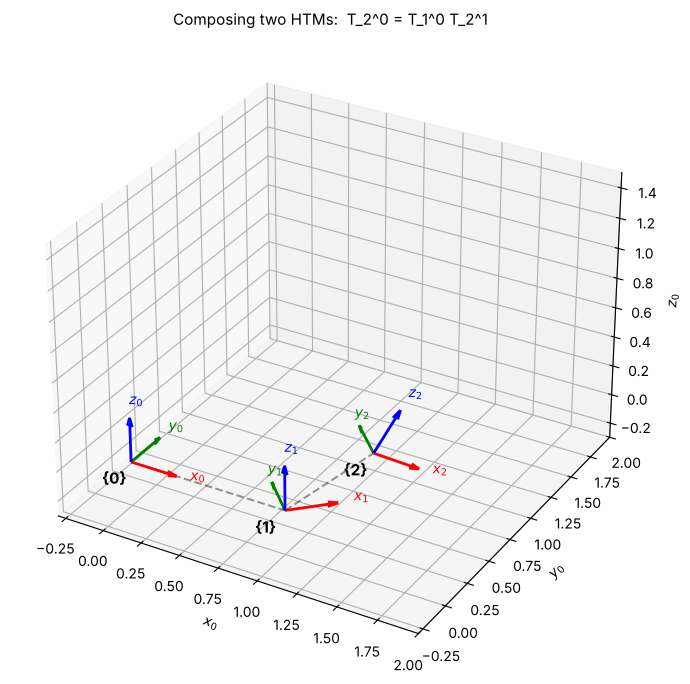

In [20]:
T10 = htm(Rz(np.radians(45)), [1.0, 0.0, 0.0])     # frame {1} relative to frame {0}
T21 = htm(Ry(np.radians(30)), [0.5, 0.0, 0.3])     # frame {2} relative to frame {1}
T20 = T10 @ T21                                    # frame {2} relative to frame {0}

print('T_1^0 =\n', T10.round(4))
print('\nT_2^1 =\n', T21.round(4))
print('\nT_2^0 = T_1^0 T_2^1 =\n', T20.round(4))

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')
for T, name in [(np.eye(4), '0'), (T10, '1'), (T20, '2')]:
    draw_frame_3d(ax, T[:3, :3], T[:3, 3], name=name, scale=0.3)
    ax.text(*(T[:3, 3] - 0.12), '{' + name + '}', fontsize=11, fontweight='bold')
origins = [T[:3, 3] for T in (np.eye(4), T10, T20)]
for a, b in zip(origins[:-1], origins[1:]):
    ax.plot(*zip(a, b), 'k--', alpha=0.4, lw=1.5)
ax.set_xlim(-0.3, 2.0); ax.set_ylim(-0.3, 2.0); ax.set_zlim(-0.3, 1.5)
ax.set_xlabel('$x_0$'); ax.set_ylabel('$y_0$'); ax.set_zlabel('$z_0$')
ax.set_title('Composing two HTMs:  T_2^0 = T_1^0 T_2^1', fontsize=11)
plt.tight_layout(); plt.show()

### 4.4.3  The inverse of an HTM

$\mathbf{T}_0^1 = (\mathbf{T}_1^0)^{-1}$ describes frame $\{0\}$ seen from frame $\{1\}$.
You don't need a general matrix inverse. Start from
$\mathbf{q}^0 = \mathbf{R}_1^0\mathbf{q}^1 + \mathbf{o}_1^0$ and solve for $\mathbf{q}^1$:
subtract $\mathbf{o}_1^0$, then multiply by $(\mathbf{R}_1^0)^\top$ (the inverse of a rotation):

$$\mathbf{q}^1 = (\mathbf{R}_1^0)^\top\mathbf{q}^0 - (\mathbf{R}_1^0)^\top\mathbf{o}_1^0
\quad\Longrightarrow\quad
\boxed{\mathbf{T}_0^1 = \left(\mathbf{T}_1^0\right)^{-1} =
\begin{bmatrix}(\mathbf{R}_1^0)^\top & -(\mathbf{R}_1^0)^\top\mathbf{o}_1^0\\ 0\ \ 0\ \ 0 & 1\end{bmatrix}}$$

Careful: the top-right block is **not** just $-\mathbf{o}_1^0$. The offset has to be
re-expressed in frame $\{1\}$'s directions too.

In [21]:
def htm_inv(T):
    # Inverse of an HTM using R^T (no general matrix inversion).
    R, o = T[:3, :3], T[:3, 3]
    return htm(R.T, -R.T @ o)


T10 = htm(Rz(np.radians(90)), [0, 1, 0])          # the worked example of 4.4.1
T01 = htm_inv(T10)
print('T_0^1 = (T_1^0)^-1 =\n', T01.round(4))
print('\nSame as np.linalg.inv?', np.allclose(T01, np.linalg.inv(T10)))
print('T_1^0 T_0^1 = I ?      ', np.allclose(T10 @ T01, np.eye(4)))
print('\n[q^1; 1] = T_0^1 [q^0; 1] =', T01 @ np.array([1, 1, 0, 1]), '  (expected [0, -1, 0, 1])')

T_0^1 = (T_1^0)^-1 =
 [[ 0.  1.  0. -1.]
 [-1.  0.  0. -0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]

Same as np.linalg.inv? True
T_1^0 T_0^1 = I ?       True

[q^1; 1] = T_0^1 [q^0; 1] = [ 0. -1.  0.  1.]   (expected [0, -1, 0, 1])


### 4.4.4  Explore an HTM

Set the origin $\mathbf{o}_1^0$ and the orientation (as ZYX yaw–pitch–roll) of frame
$\{1\}$. The black point is fixed **in frame $\{1\}$** at $\mathbf{q}^1 = (0.5,\ 0,\ 0)$ — half a
unit along $x_1$ — so it rides along with the frame. Its frame-$\{0\}$ coordinates are
computed with $\tilde{\mathbf{q}}^0 = \mathbf{T}_1^0\tilde{\mathbf{q}}^1$.

In [22]:
def htm_explorer(o_x, o_y, o_z, yaw_deg, pitch_deg, roll_deg):
    o10 = np.array([o_x, o_y, o_z])
    R10 = Rz(np.radians(yaw_deg)) @ Ry(np.radians(pitch_deg)) @ Rx(np.radians(roll_deg))
    T10 = htm(R10, o10)
    q1 = np.array([0.5, 0, 0])
    q0 = (T10 @ np.append(q1, 1))[:3]

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection='3d')
    draw_frame_3d(ax, np.eye(3), name='0', scale=0.6, alpha=0.6)
    draw_frame_3d(ax, R10, o10, name='1', scale=0.6)
    ax.plot(*zip(np.zeros(3), o10), 'k--', alpha=0.35, lw=1.5)
    ax.scatter(*q0, color='black', s=60)
    ax.text(*(q0 + 0.1), 'q', fontsize=12, fontweight='bold')
    setup_3d(ax, 2.0, 'Frame {1} relative to frame {0}')
    plt.tight_layout(); plt.show()
    print('T_1^0 =\n', T10.round(4))
    print('\nq^1 =', q1, '   ->   q^0 =', q0.round(4))


interact(htm_explorer,
         o_x=FloatSlider(value=1.0, min=-1.5, max=1.5, step=0.1, description='o_x'),
         o_y=FloatSlider(value=0.5, min=-1.5, max=1.5, step=0.1, description='o_y'),
         o_z=FloatSlider(value=0.5, min=-1.5, max=1.5, step=0.1, description='o_z'),
         yaw_deg  =FloatSlider(value=30, min=-180, max=180, step=5, description='Yaw ψ (z)'),
         pitch_deg=FloatSlider(value=20, min=-90,  max=90,  step=5, description='Pitch θ (y)'),
         roll_deg =FloatSlider(value=10, min=-180, max=180, step=5, description='Roll φ (x)'));

interactive(children=(FloatSlider(value=1.0, description='o_x', max=1.5, min=-1.5), FloatSlider(value=0.5, des…

> **Key Takeaways — Section 4.4**
> - $\mathbf{T}_1^0 = \begin{bmatrix}\mathbf{R}_1^0 & \mathbf{o}_1^0\\ \mathbf{0}^\top & 1\end{bmatrix}$ ($4\times4$): its columns are $\mathbf{x}_1^0, \mathbf{y}_1^0, \mathbf{z}_1^0, \mathbf{o}_1^0$.
> - Transform points with a single multiply: $\tilde{\mathbf{q}}^0 = \mathbf{T}_1^0\,\tilde{\mathbf{q}}^1$.
> - Chain frames: $\mathbf{T}_C^A = \mathbf{T}_B^A\,\mathbf{T}_C^B$ (inner indices cancel).
> - Invert without a general inverse: $\mathbf{T}_0^1 = \begin{bmatrix}(\mathbf{R}_1^0)^\top & -(\mathbf{R}_1^0)^\top\mathbf{o}_1^0\\ \mathbf{0}^\top & 1\end{bmatrix}$.

## 4.5  Chapter Summary and Practice

### Cheat sheet

| What | 2D | 3D |
|------|----|----|
| Rotation matrix | $\mathbf{R}_1^0 = [\mathbf{x}_1^0\ \ \mathbf{y}_1^0]$, $2\times2$ | $\mathbf{R}_1^0 = [\mathbf{x}_1^0\ \ \mathbf{y}_1^0\ \ \mathbf{z}_1^0]$, $3\times3$ |
| Convert a point (same origin) | $\mathbf{q}^0 = \mathbf{R}_1^0\mathbf{q}^1$ | same |
| Go back | $\mathbf{R}_0^1 = (\mathbf{R}_1^0)^\top$ | same |
| Moved + turned frame | $\mathbf{q}^0 = \mathbf{R}_1^0\mathbf{q}^1 + \mathbf{o}_1^0$ | same |
| HTM | $\mathbf{T}_1^0 = \begin{bmatrix}\mathbf{R}_1^0 & \mathbf{o}_1^0\\ \mathbf{0}^\top & 1\end{bmatrix}$, $3\times3$ | same blocks, $4\times4$ |
| Transform a point | $\tilde{\mathbf{q}}^0 = \mathbf{T}_1^0\tilde{\mathbf{q}}^1$ | same |
| Chain frames | $\mathbf{T}_C^A = \mathbf{T}_B^A\mathbf{T}_C^B$ | same |
| Combine rotations | order doesn't matter | **order matters**; right = current axes |

**Looking ahead.** Chapter 5 adds two things: six **basic HTMs**
($\mathrm{Trans}_{x,a}$, $\mathrm{Trans}_{y,b}$, $\mathrm{Trans}_{z,c}$, $\mathrm{Rot}_{x,\alpha}$,
$\mathrm{Rot}_{y,\beta}$, $\mathrm{Rot}_{z,\gamma}$ — the pure translations and the HTM versions of
$\mathbf{R}_x$, $\mathbf{R}_y$, $\mathbf{R}_z$), and a three-step recipe that uses them to write
$\mathbf{T}_e^0$ for any robot arm.

### Practice problems

Try each one on paper first, then expand the answer or check it with the code cell below.

**P1 (2D HTM).** Frame $\{1\}$ has origin $\mathbf{o}_1^0 = (2, 0)$ and is turned by $90^\circ$.
A point has $\mathbf{q}^1 = (1, 0)$. Find $\mathbf{q}^0$.

<details><summary>Answer</summary>

$\mathbf{R}_1^0 = \begin{bmatrix}0&-1\\1&0\end{bmatrix}$, so
$\mathbf{q}^0 = \mathbf{R}_1^0\mathbf{q}^1 + \mathbf{o}_1^0 = (0, 1) + (2, 0) = (2, 1)$.
</details>

**P2 (3D rotation matrix).** $x_1$ points along $-y_0$, $y_1$ points along $x_0$. Where does
$z_1$ point? Write $\mathbf{R}_1^0$ and $\mathbf{R}_0^1$.

<details><summary>Answer</summary>

$\mathbf{z}_1^0 = \mathbf{x}_1^0\times\mathbf{y}_1^0 = (0,-1,0)\times(1,0,0) = (0,0,1)$, so $z_1$ points along $z_0$.
$\mathbf{R}_1^0 = \begin{bmatrix}0&1&0\\-1&0&0\\0&0&1\end{bmatrix} = \mathbf{R}_z(-90^\circ)$,
$\ \mathbf{R}_0^1 = (\mathbf{R}_1^0)^\top = \begin{bmatrix}0&-1&0\\1&0&0\\0&0&1\end{bmatrix}$.
</details>

**P3 (order of rotations).** A frame is first turned $90^\circ$ about $z_0$, then $90^\circ$
about its **own new** $x$ axis. Write the total rotation as a product of basic rotation
matrices. Then do the same if the second turn is about the **fixed** $x_0$ axis.

<details><summary>Answer</summary>

Current (own) axis → multiply on the right: $\mathbf{R} = \mathbf{R}_z(90^\circ)\,\mathbf{R}_x(90^\circ)$.
Fixed axis → multiply on the left: $\mathbf{R} = \mathbf{R}_x(90^\circ)\,\mathbf{R}_z(90^\circ)$.
They are different matrices.
</details>

**P4 (chaining HTMs).** $\mathbf{T}_1^0$ has $\mathbf{R}_1^0 = \mathbf{R}_z(90^\circ)$,
$\mathbf{o}_1^0 = (1, 0, 0)$. $\mathbf{T}_2^1$ has $\mathbf{R}_2^1 = \mathbf{I}$,
$\mathbf{o}_2^1 = (2, 0, 0)$. Where is the origin of frame $\{2\}$ in frame $\{0\}$?

<details><summary>Answer</summary>

$\mathbf{o}_2^0 = \mathbf{R}_1^0\,\mathbf{o}_2^1 + \mathbf{o}_1^0 = (0, 2, 0) + (1, 0, 0) = (1, 2, 0)$
— the last column of $\mathbf{T}_2^0 = \mathbf{T}_1^0\mathbf{T}_2^1$.
</details>

In [23]:
# Check your answers to P1-P4
# P1
T10 = htm_2d(np.radians(90), [2, 0])
print('P1: q^0 =', (T10 @ [1, 0, 1])[:2])

# P2
x1, y1 = np.array([0, -1, 0]), np.array([1, 0, 0])
R10 = np.column_stack([x1, y1, np.cross(x1, y1)])
print('\nP2: R_1^0 =\n', R10, '\n    equals R_z(-90°)?', np.allclose(R10, Rz(np.radians(-90))))

# P3
print('\nP3: current axis R_z R_x =\n', (Rz(np.pi/2) @ Rx(np.pi/2)).round(4))
print('    fixed axis   R_x R_z =\n', (Rx(np.pi/2) @ Rz(np.pi/2)).round(4))

# P4
T10 = htm(Rz(np.radians(90)), [1, 0, 0])
T21 = htm(np.eye(3), [2, 0, 0])
print('\nP4: o_2^0 =', (T10 @ T21)[:3, 3].round(4))

P1: q^0 = [2. 1.]

P2: R_1^0 =
 [[ 0  1  0]
 [-1  0  0]
 [ 0  0  1]] 
    equals R_z(-90°)? True

P3: current axis R_z R_x =
 [[ 0. -0.  1.]
 [ 1.  0. -0.]
 [ 0.  1.  0.]]
    fixed axis   R_x R_z =
 [[ 0. -1.  0.]
 [ 0.  0. -1.]
 [ 1.  0.  0.]]

P4: o_2^0 = [1. 2. 0.]
